# PF8 03websmog: smog data for the web page

Reads the outputs of 02smogdata and writes `docs/data/smog.json`, the small file that drives the smog in the 3D scene:

- **PM2.5 per station per hour** (SINCA 24-hour rolling average through OpenAQ), with a known glitch removed (Section 2). The page spreads the station values across the basin itself.
- **Two lid heights per hour** from ERA5 (Section 3):
  - the **mixing layer**: ERA5 boundary layer height, the depth of turbulent mixing above the ground. At night it is only 15 to 30 m.
  - the **residual layer**: smog mixed up during the afternoon stays aloft overnight below the inversion. Modelled here as the boundary layer height or the decayed previous value, whichever is higher. This is a simple illustration of a real process, labelled as such on the page.
- **10 m wind** per hour (for drifting particles) and 2 m temperature.

## 0. Settings

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
OUT_FILE = Path("docs") / "data" / "smog.json"
TIMEZONE = "America/Santiago"

GLITCH_MIN_STEP = 10.0  # <- a jump of at least this much (ug/m3) that reverses 24 hours later is treated as one bad hourly reading
GLITCH_MATCH = 0.7  # <- the reverse jump must be at least this fraction of the first
MAX_GLITCH_HOURS = 24  # <- the reverse jump must come within this many hours
CITY_MAX_ELEV_M = 800  # <- ERA5 points whose ground is above this are in the mountains and left out of the city lid
RESIDUAL_DECAY_PER_HOUR = 0.97  # <- VISUAL: how fast the residual layer thins overnight (0.97 keeps about 60% after 16 hours)
BASE_ALT_M = 500  # <- altitude (m above sea level) the lid heights are measured from: the western basin floor

## 1. Read

In [2]:
pm = pd.read_csv(DATA_DIR / "pm25_stations.csv")
pm["time_utc"] = pd.to_datetime(pm["time_utc"], utc=True)
era5 = pd.read_csv(DATA_DIR / "era5_hourly.csv")
era5["time_utc"] = pd.to_datetime(era5["time_utc"], utc=True)
print(f"{len(pm):,} station hours, {pm['station'].nunique()} stations; {len(era5):,} ERA5 point hours")

1,935 station hours, 9 stations; 1,944 ERA5 point hours


## 2. Remove one-hour glitches

A 24-hour rolling average changes slowly, so a sudden jump of 10 ug/m3 or more in one hour that reverses within a day is an artefact (El Bosque, 12 June: +18 at 01:00, back down at 10:00). Where that pattern appears, the jump is subtracted from the hours in between.

In [3]:
wide = pm.pivot_table(index="time_utc", columns="station", values="pm25_24h")
hours = pd.date_range(wide.index.min(), wide.index.max(), freq="h")
wide = wide.reindex(hours)
fixes = []
for st in wide.columns:
    s = wide[st].copy()
    d = s.diff()
    i = 1
    while i < len(s) - 1:
        jump = d.iloc[i]
        if pd.notna(jump) and abs(jump) >= GLITCH_MIN_STEP:
            for k in range(1, MAX_GLITCH_HOURS + 1):
                if i + k >= len(s):
                    break
                back = d.iloc[i + k]
                if pd.notna(back) and back * jump < 0 and abs(back) >= GLITCH_MATCH * abs(jump):
                    s.iloc[i:i + k] = s.iloc[i:i + k] - jump
                    fixes.append((st, s.index[i].tz_convert(TIMEZONE), round(jump, 1), k))
                    i = i + k
                    break
        i = i + 1
    wide[st] = s
for f in fixes:
    print(f"Fixed {f[0]}: jump of {f[2]} at {f[1]:%d %b %H:%M}, reversed after {f[3]} hours")
if not fixes:
    print("No glitches found")

gaps = wide.isna().sum()
wide = wide.interpolate(limit=3, limit_direction="both")
print()
print("Missing hours filled (up to 3 in a row):", gaps[gaps > 0].to_dict())
print("Still missing:", wide.isna().sum()[wide.isna().sum() > 0].to_dict())

Fixed El Bosque: jump of 18.0 at 12 Jun 01:00, reversed after 9 hours

Missing hours filled (up to 3 in a row): {}
Still missing: {}


## 3. City lid: mixing layer and residual layer

In [4]:
points = era5.groupby("point")[["lat_grid", "lon_grid", "grid_elev"]].first()
city_points = points[points["grid_elev"] <= CITY_MAX_ELEV_M].index
print("ERA5 points used for the city:")
print(points.loc[city_points].to_string())

city = era5[era5["point"].isin(city_points)].copy()
rad = np.radians(city["wind_direction_10m"])
city["u"] = -city["wind_speed_10m"] * np.sin(rad)
city["v"] = -city["wind_speed_10m"] * np.cos(rad)
lid = city.groupby("time_utc").agg(blh=("boundary_layer_height", "mean"), u=("u", "mean"), v=("v", "mean"), t2m=("temperature_2m", "mean"))
lid = lid.reindex(hours).interpolate(limit_direction="both")

residual = []
r = 0.0
for b in lid["blh"]:
    r = max(b, r * RESIDUAL_DECAY_PER_HOUR)
    residual.append(r)
lid["residual"] = residual
lid["wind_kmh"] = np.hypot(lid["u"], lid["v"]) * 3.6
local = lid.copy()
local.index = local.index.tz_convert(TIMEZONE)
print()
print(local.resample("D").agg({"blh": ["min", "max"], "residual": ["min", "max"], "wind_kmh": "mean"}).round(0).to_string())

ERA5 points used for the city:
       lat_grid  lon_grid  grid_elev
point                               
0        -33.25    -70.75      486.0
1        -33.25    -70.75      546.0
3        -33.50    -70.75      469.0
4        -33.50    -70.75      554.0
6        -33.50    -70.75      409.0
7        -33.50    -70.75      617.0

                            blh        residual        wind_kmh
                            min    max      min    max     mean
2026-06-11 00:00:00-04:00  15.0  373.0     20.0  373.0     21.0
2026-06-12 00:00:00-04:00  13.0  142.0    137.0  275.0     18.0
2026-06-13 00:00:00-04:00  15.0  412.0     95.0  412.0     13.0
2026-06-14 00:00:00-04:00  13.0  380.0    211.0  380.0     15.0
2026-06-15 00:00:00-04:00  15.0  323.0    194.0  323.0     15.0
2026-06-16 00:00:00-04:00  15.0  235.0    171.0  246.0     14.0
2026-06-17 00:00:00-04:00  15.0  462.0    128.0  462.0     16.0
2026-06-18 00:00:00-04:00  20.0  685.0    251.0  685.0     14.0
2026-06-19 00:00:00-04:00  12.0 

## 4. Chart: the two layers and the dirtiest station

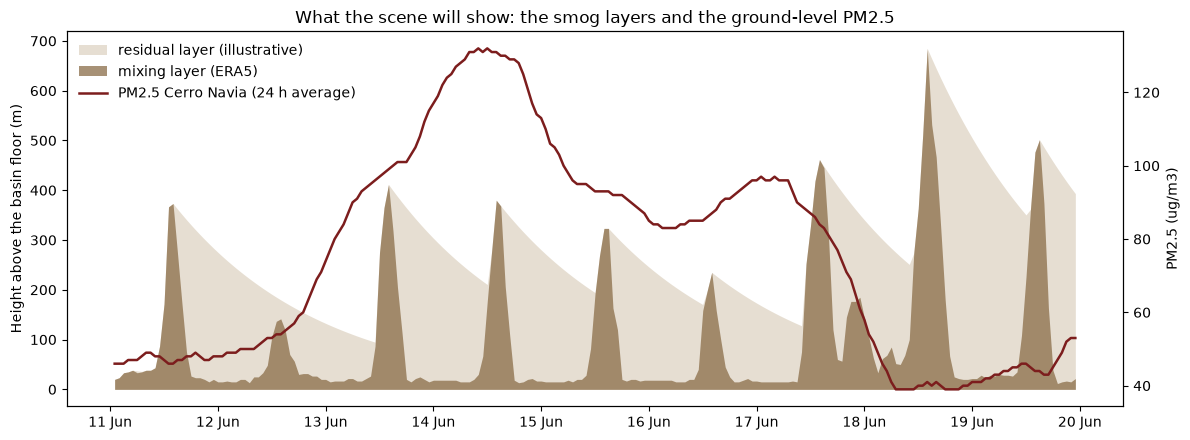

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

worst = wide.max().idxmax()
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.fill_between(local.index, 0, local["residual"], color="#c9b79c", alpha=0.45, lw=0, label="residual layer (illustrative)")
ax1.fill_between(local.index, 0, local["blh"], color="#8a6d48", alpha=0.75, lw=0, label="mixing layer (ERA5)")
ax1.set_ylabel("Height above the basin floor (m)")
ax2 = ax1.twinx()
ax2.plot(local.index, wide[worst].values, color="#7c1d1d", lw=1.8, label=f"PM2.5 {worst} (24 h average)")
ax2.set_ylabel("PM2.5 (ug/m3)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=TIMEZONE))
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper left")
ax1.set_title("What the scene will show: the smog layers and the ground-level PM2.5")
plt.tight_layout()
plt.savefig(DATA_DIR / "chart_layers.png", dpi=130)
plt.show()

## 5. Write the JSON

```
{"meta": {...}, "times": ["2026-06-11T00:00:00-04:00", ...],
 "stations": [{"name", "lon", "lat"}, ...], "pm25": [[one value per station] per hour],
 "blh": [...], "residual": [...], "u": [...], "v": [...], "t2m": [...]}
```

Times are Santiago local time with their offset. Heights are metres above BASE_ALT_M.

In [6]:
meta_st = pm.groupby("station")[["lon", "lat"]].first()
station_names = list(wide.columns)
data = {
    "meta": {
        "base_alt_m": BASE_ALT_M,
        "pm25_note": "SINCA PM2.5, 24-hour rolling average, via the OpenAQ archive",
        "lid_note": "ERA5 boundary layer height via Open-Meteo, mean of the city grid points; residual layer illustrative",
        "residual_decay_per_hour": RESIDUAL_DECAY_PER_HOUR,
        "glitch_fixes": [f"{f[0]} {f[1]:%d %b %H:%M} {f[2]} for {f[3]} h" for f in fixes],
    },
    "times": [t.tz_convert(TIMEZONE).isoformat() for t in hours],
    "stations": [{"name": n, "lon": round(float(meta_st.loc[n, "lon"]), 5), "lat": round(float(meta_st.loc[n, "lat"]), 5)} for n in station_names],
    "pm25": [[None if pd.isna(x) else round(float(x), 1) for x in row] for row in wide[station_names].values],
    "blh": [round(float(x), 1) for x in lid["blh"]],
    "residual": [round(float(x), 1) for x in lid["residual"]],
    "u": [round(float(x), 2) for x in lid["u"]],
    "v": [round(float(x), 2) for x in lid["v"]],
    "t2m": [round(float(x), 1) for x in lid["t2m"]],
}
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
OUT_FILE.write_text(json.dumps(data, separators=(",", ":"), ensure_ascii=False), encoding="utf-8")
print(f"Wrote {len(hours)} hours, {len(station_names)} stations to {OUT_FILE} ({OUT_FILE.stat().st_size / 1e3:.0f} kB)")

Wrote 215 hours, 9 stations to docs\data\smog.json (23 kB)


___
**END**